# Bioinformatics of Cell Junction Proteins

## This notebook extracts proteins associated with cell junctions, as well as proteins with IDRs and examines their domain and IDR architectures

### The following was used to extract the proteins of interest
* Accessions were extracted from Uniprot using the GO term 0030054 for Cell junctions (data/uniprotkb_organism_id_9606_AND_go_00300_2025_09_24.list)
* These acessions were filtered to exclude any proteins that had a transmembrane domain using KW-0812 in Uniprot (data/uniprotkb_keyword_KW_0812_AND_model_org_2025_09_24.list)
* IDR containing proteins were extracted using the method from the GIN manuscript. Briefly, MobiDB was used to predict all IDRs of length ≥ 30. Then a filtering was performed to extract IDRs of length ≥ 70 and non-linker IDRs of length ≥ 50. This criterion helps idenitfy IDRs likely to play functional roles within the context of the full protein. 
* Additionally only accessions in which the length of the full protein was consistent in the IDR dataset and domain dataset were considered. The reason for some mismatches is that Uniprot changed which isoform was the main isoform between cases. Thus, to avoid mismatch in where domains should match to we just remove all cases of mismatch upfront

# Part 0: Load in libraries needed

In [19]:
import numpy as np
import pandas as pd
import seaborn as sbn
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
import localcider
from localcider.sequenceParameters import SequenceParameters
import re
import math
import scipy
from scipy.stats import ks_2samp
from matplotlib.patches import Rectangle
import pathlib
from matplotlib import font_manager
from scipy.stats import fisher_exact


# Setup the fonts
fonts_path = pathlib.Path.home().joinpath('fonts') # i.e. `~/fonts` (update as needed)
font_filename = 'ARIAL.TTF'
font_path = fonts_path.joinpath(font_filename)
print(font_path)

font_manager.fontManager.addfont(str(font_path))
prop = font_manager.FontProperties(fname=font_path)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()
plt.rcParams['pdf.fonttype'] = 42 # Makes text editiable
plt.rcParams['ps.fonttype'] = 42

COLOR_MAP = dict()
COLOR_MAP['A']         = '#8c8c8c'
COLOR_MAP['CHNQST']    = '#077a15'
COLOR_MAP['DE']        = '#e23a36'
COLOR_MAP['FWY']       = '#f58220'
COLOR_MAP['G']         = '#86bd8d'
COLOR_MAP['ILMV']      = '#231f20'
COLOR_MAP['KR']        = '#1725c2'
COLOR_MAP['P']         = '#c25fc9'


# Using the global color map, we convert the colormap of amino acid
# groups, to a map against individual amino acids. This
# serves as our internal color map which is used for styling.
aacolor_map=dict()
for amino_acids in COLOR_MAP:
    for amino_acid in amino_acids:
        aacolor_map[amino_acid] = COLOR_MAP[amino_acids]

/home/compute/kiersten.ruff/fonts/ARIAL.TTF


# Part 1: Extract and analyze data

## 1.1 - Get all IDR information and Domain information

In [20]:
# Load in IDR information from MobiDB
humandf=pd.read_excel('data/All_sapiens_IDRs_w_zscores_updated.xlsx')
#print(humandf.isnull().any())
humandf = humandf.fillna('')
tmpfullaccs=humandf['Uniprot'].tolist()
tmpfullproteinlength=humandf['Full Protein Length'].tolist()
print('Number of unique IDRs ≥ 30: '+str(len(humandf)))

# Load in domain information
domaindf=pd.read_excel('data/sapiens_from_fasta_uniprot_all_domains_start_end_name.xlsx')
domainlens=domaindf['Length'].tolist()
domainaccs=domaindf['Accession'].tolist()
print('Number of human Domains: '+str(len(domaindf)))

# Remove all domain entries whose length of protein does not match length of protein from IDR dataframe
# Similarly remove all IDR entries whose length of protein does not match length of protein from IDR dataframe
# Such a mismatch can occur when Uniprot has switched which is the main isoform of the protein between 
# when I grabbed IDRs and when I grabbed domains
badacclist=[]
for i in range(0,len(domainaccs)):
    if domainaccs[i] in tmpfullaccs:
        # Check if length matches
        idx=tmpfullaccs.index(domainaccs[i])
        tlen=tmpfullproteinlength[idx]
        if domainlens[i]!=tlen and domainaccs[i] not in badacclist:
            #print(tmpfullgeneswnums[idx])
            #print(tlen)
            #print(domainlens[i])
            badacclist.append(domainaccs[i])            

domaindf=domaindf[~domaindf['Accession'].isin(badacclist)]
print('Number of human Domains with consistent IDR protein info: '+str(len(domaindf)))

humandf=humandf[~humandf['Uniprot'].isin(badacclist)]
print('Number of human IDRs ≥ 30 with consistent domain protein info: '+str(len(humandf)))

fullaccs=humandf['Uniprot'].tolist()
fullaccswnums=humandf['Uniprot w IDRnum'].tolist()
fullgeneswnums=humandf['Gene'].tolist()
fullclusternum=humandf['Cluster Number'].tolist()
fullseqlens=humandf['IDR Length'].tolist()
fullstpos=humandf['Start Pos'].tolist()
fullenpos=humandf['End Pos'].tolist()
fullproteinlength=humandf['Full Protein Length'].tolist()
fullmininterclustdist=humandf['Min Inter Clust Dist'].tolist()
fulltermini=humandf['IDR Position'].tolist()
fulllocationbyunistring=humandf['HPA Location'].tolist()
fullseqs=humandf['Sequence'].tolist()

print('Number of unique proteins housing IDRs ≥ 30: '+str(len(list(set(fullaccs)))))

print(len(badacclist))
print(len(list(set(tmpfullaccs))))

Number of unique IDRs ≥ 30: 24508
Number of human Domains: 20688
Number of human Domains with consistent IDR protein info: 19898
Number of human IDRs ≥ 30 with consistent domain protein info: 23778
Number of unique proteins housing IDRs ≥ 30: 10508
178
10686


## 1.2 - Create subset of IDRs that want to analyze - all IDRs length gte 70 and non-linker IDRs gte 50 in length and min inter cluster distance gte 1.5

* The 1.5 criterion is only used when we care about the mapped GIN cluster of the IDR
* Below this IDRs are very weakly mapped

In [21]:
minidrlength=50
minidrlinkerlength=70
mininterclustdist=1.5

subidrsdf=humandf[humandf['IDR Length']>=minidrlength]
subidrsdf=subidrsdf[ (subidrsdf['IDR Length']>=minidrlinkerlength) | (subidrsdf['IDR Position'].isin(['IDR','N-terminal IDR','C-terminal IDR'])) ]
subidrsdf=subidrsdf[subidrsdf['Min Inter Clust Dist']>=mininterclustdist]
#print(subidrsdf.isnull().any())
subidrsdf = subidrsdf.fillna('')
#print(subidrsdf)

subaccs=subidrsdf['Uniprot'].tolist()
subaccswnums=subidrsdf['Uniprot w IDRnum'].tolist()
subgeneswnums=subidrsdf['Gene'].tolist()
subclusters=subidrsdf['Cluster Number'].tolist()
subseqlens=subidrsdf['IDR Length'].tolist()
substpos=subidrsdf['Start Pos'].tolist()
subenpos=subidrsdf['End Pos'].tolist()
subproteinlength=subidrsdf['Full Protein Length'].tolist()
submininterclustdist=subidrsdf['Min Inter Clust Dist'].tolist()
subtermini=subidrsdf['IDR Position'].tolist()
subseqs=subidrsdf['Sequence'].tolist()
sublocstring=subidrsdf['HPA Location'].tolist()


sublocationbyunistring=sublocstring

print('Number of unique IDRs ≥ 70 and non-linker IDRs ≥ 50: '+str(len(subidrsdf)))
print('Number of unique proteins housing IDRs ≥ 70 and non-linker IDRs ≥ 50: '+str(len(list(set(subaccs)))))

Number of unique IDRs ≥ 70 and non-linker IDRs ≥ 50: 8308
Number of unique proteins housing IDRs ≥ 70 and non-linker IDRs ≥ 50: 5603


## 1.2b - Create subset of IDRs that want to analyze - all IDRs length gte 70 and non-linker IDRs gte 50 in length - used when don't care about cluster distance

In [22]:
subidrsdfNODIST=humandf[humandf['IDR Length']>=minidrlength]
subidrsdfNODIST=subidrsdfNODIST[ (subidrsdfNODIST['IDR Length']>=minidrlinkerlength) | (subidrsdfNODIST['IDR Position'].isin(['IDR','N-terminal IDR','C-terminal IDR'])) ]
#print(subidrsdfNODIST.isnull().any())
subidrsdfNODIST = subidrsdfNODIST.fillna('')
#print(subidrsdfNODIST)

subaccsNODIST=subidrsdfNODIST['Uniprot'].tolist()
subaccswnumsNODIST=subidrsdfNODIST['Uniprot w IDRnum'].tolist()
subgeneswnumsNODIST=subidrsdfNODIST['Gene'].tolist()
subclustersNODIST=subidrsdfNODIST['Cluster Number'].tolist()
subseqlensNODIST=subidrsdfNODIST['IDR Length'].tolist()
substposNODIST=subidrsdfNODIST['Start Pos'].tolist()
subenposNODIST=subidrsdfNODIST['End Pos'].tolist()
subproteinlengthNODIST=subidrsdfNODIST['Full Protein Length'].tolist()
submininterclustdistNODIST=subidrsdfNODIST['Min Inter Clust Dist'].tolist()
subterminiNODIST=subidrsdfNODIST['IDR Position'].tolist()
subseqsNODIST=subidrsdfNODIST['Sequence'].tolist()
sublocstringNODIST=subidrsdfNODIST['HPA Location'].tolist()

sublocationbyunistringNODIST=sublocstringNODIST

print('Number of unique IDRs ≥ 70 and non-linker IDRs ≥ 50: '+str(len(subidrsdfNODIST)))
print('Number of unique proteins housing IDRs ≥ 70 and non-linker IDRs ≥ 50: '+str(len(list(set(subaccsNODIST)))))

Number of unique IDRs ≥ 70 and non-linker IDRs ≥ 50: 9813
Number of unique proteins housing IDRs ≥ 70 and non-linker IDRs ≥ 50: 6269


## 1.3 - Get accessions of proteins with Cell junction GO term 0030054 and without transmembrane domains (KW_0812)

In [23]:
## Load in cell junction GO term proteins
cjuaccsdf=pd.read_table('data/uniprotkb_organism_id_9606_AND_go_00300_2025_09_24.list',header=None)
## remove proteins from bad accession list
cjuaccsdf=cjuaccsdf[~cjuaccsdf[0].isin(badacclist)]
cjuaccs=cjuaccsdf[0].tolist()
print('Number of unique proteins in cell junctions: '+str(len(cjuaccs)))

## Load in transmembrane proteins
tmaccsdf=pd.read_table('data/uniprotkb_keyword_KW_0812_AND_model_org_2025_09_24.list',header=None)
tmaccs=tmaccsdf[0].tolist()

## Get cell junction accessions that are not transmembrane proteins
cjunmaccs=[]
for i in range(0,len(cjuaccs)):
    if cjuaccs[i] not in tmaccs:
        cjunmaccs.append(cjuaccs[i])
print('Number of unique proteins in cell junctions without transmembrane domains: '+str(len(cjunmaccs)))

## Get the subset of IDRs that correspond to cell junction proteins without transmembrane domains
cjudf=subidrsdfNODIST.copy()
cjudf=cjudf[cjudf['Uniprot'].isin(cjunmaccs)]

print('Number of unique IDRs ≥ 70 and non-linker IDRs ≥ 50 in cell junction proteins without transmembrane domains: '+str(len(cjudf)))

## Unique accessions of proteins an IDR and in cell junctions without transmembrane domains
uniUni=list(set(cjudf['Uniprot'].tolist()))

print('Number of unique cell junction without transmembrane domain proteins housing IDRs ≥ 70 & non-linker IDRs ≥ 50: '+str(len(uniUni)))

## Excel file of all human IDRs in cell junction without transmembrane domains proteins
#cjudf.to_excel('output/Human_IDRs_in_cell_junction_without_transmembrane_proteins.xlsx')

Number of unique proteins in cell junctions: 2379
Number of unique proteins in cell junctions without transmembrane domains: 1510
Number of unique IDRs ≥ 70 and non-linker IDRs ≥ 50 in cell junction proteins without transmembrane domains: 1126
Number of unique cell junction without transmembrane domain proteins housing IDRs ≥ 70 & non-linker IDRs ≥ 50: 625


## 1.4 - Data to plot venn diagram of Cell junction proteins and proteins with at least one IDR

In [6]:
print('Number of unique proteins in cell junctions without transmembrane domains: '+str(len(cjunmaccs)))
print('Number of unique proteins housing IDRs ≥ 70 and non-linker IDRs ≥ 50: '+str(len(list(set(subaccsNODIST)))))
print('Number of unique cell junction without transmembrane domain proteins housing IDRs ≥ 70 & non-linker IDRs ≥ 50: '+str(len(uniUni)))

Number of unique proteins in cell junctions without transmembrane domains: 1510
Number of unique proteins housing IDRs ≥ 70 and non-linker IDRs ≥ 50: 6269
Number of unique cell junction without transmembrane domain proteins housing IDRs ≥ 70 & non-linker IDRs ≥ 50: 625


## 1.5 - Plot venn diagram

     Proteins Housing Long IDRs Cell-Cell Junction Proteins in Cytosol Overlap
0                        Q8WWM7                                 Q9UGC6  Q99569
1                        Q7Z3H4                                 P50395  Q9ULU8
2                        Q8N9L1                                 Q6ISB3  O95425
3                        Q96EZ8                                 Q9BZR6  P09016
4                        P16403                                 O60282  Q9BZR6
...                         ...                                    ...     ...
6264                     Q9NWT1                                    NaN     NaN
6265                     O15231                                    NaN     NaN
6266                     O43609                                    NaN     NaN
6267                     O60829                                    NaN     NaN
6268                     Q8TF61                                    NaN     NaN

[6269 rows x 3 columns]


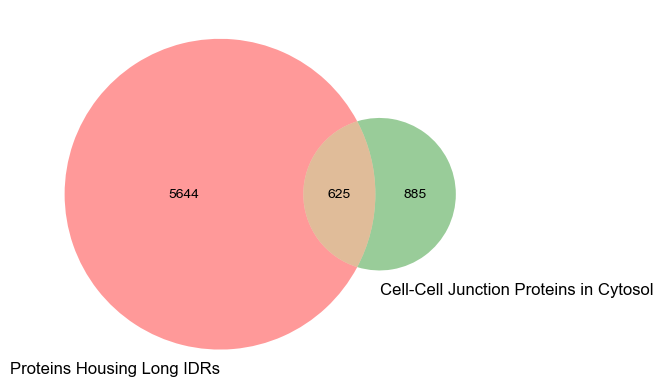

In [24]:
# to run this make sure matplotlib-venn is installed
from matplotlib_venn import venn2

# Define your data collections
group_a = set(subaccsNODIST)
group_b = set(cjunmaccs)
ovla_ab = group_a & group_b

vddf=pd.DataFrame()
vddf['Proteins Housing Long IDRs']=pd.Series(list(set(subaccsNODIST)))
vddf['Cell-Cell Junction Proteins in Cytosol']=pd.Series(list(set(cjunmaccs)))
vddf['Overlap']=pd.Series(list(ovla_ab))
print(vddf)

#vddf.to_excel('output/Accessions_for_venn_diagram.xlsx')

# Plot the 2-circle Venn diagram
venn2([group_a, group_b], set_labels=('Proteins Housing Long IDRs', 'Cell-Cell Junction Proteins in Cytosol'))

#plt.savefig('Venn_diagram_proteins_housing_IDRs_and_cytosolic_cell_junction_proteins.pdf', transparent=True, bbox_inches = "tight")


## 1.6 - Extract domains in proteins with IDRs and in cell junctions

In [25]:
# Subset of domains for just cell junction IDR containing proteins
cjdomaindf=domaindf[domaindf['Accession'].isin(uniUni)]

# Add domain name with no trailing number
domainnamenonum=[]
for i in range(0,len(cjdomaindf)):
    domain=cjdomaindf['Domain name'].tolist()[i]
    domainnamenonum.append(re.sub(r'\s+\d+$', '', domain))
    
cjdomaindf['Domain name no num']=domainnamenonum
print(cjdomaindf)   

# Write excel file of subset of domains for just cell junction IDR containing proteins
#cjdomaindf.to_excel('output/Human_Domains_in_proteins_w_IDRs_and_cell_junction_without_transmembrane_proteins.xlsx')

/tmp/ipykernel_2872478/2027525436.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cjdomaindf['Domain name no num']=domainnamenonum


       Unnamed: 0 Accession                          Gene  Length  Start pos  \
108           108    A1X283  SH3PXD2B FAD49 KIAA1295 TKS4     911          5   
109           109    A1X283  SH3PXD2B FAD49 KIAA1295 TKS4     911        152   
110           110    A1X283  SH3PXD2B FAD49 KIAA1295 TKS4     911        221   
111           111    A1X283  SH3PXD2B FAD49 KIAA1295 TKS4     911        368   
112           112    A1X283  SH3PXD2B FAD49 KIAA1295 TKS4     911        850   
...           ...       ...                           ...     ...        ...   
20510       20510    Q9Y613              FHOD1 FHOS FHOS1    1164        487   
20511       20511    Q9Y613              FHOD1 FHOS FHOS1    1164        616   
20512       20512    Q9Y613              FHOD1 FHOS FHOS1    1164       1053   
20619       20619    Q9Y6R0                         NUMBL     609         74   
20658       20658    Q9Y6W5                   WASF2 WAVE2     498        436   

       End pos Domain name Domain name 

## 1.7 - Count domains by type

In [50]:
# Get the unique domain names in the table DataFrame of all domains from proteins with IDRs and in cell junctions without transmembrane domains
cjdomainlist=cjdomaindf['Domain name no num'].tolist()
unicjdomainlist=sorted(list(set(cjdomainlist)))
print(len(unicjdomainlist))
#unicjdomainlist = sorted(list(set(re.sub(r'\s+\d+$', '', domain) for domain in cjdomainlist)))
#print(unique_domains)
#hi

# For each unique domain count the number of occurrences in the full domain list
countdomains=[]
for i in unicjdomainlist:
    countdomains.append(sum(s.count(i) for s in cjdomainlist))   
#print(countdomains)

# Create dataframe of counts per domain type
countdomaindf=pd.DataFrame()
countdomaindf['Domain Name']=unicjdomainlist
countdomaindf['Count']=countdomains
countdomaindf=countdomaindf.sort_values(by='Count',ascending=False)
print(countdomaindf.head(50))

# Save excel file of domain counts in proteins with IDRs and in cell junctions 
#countdomaindf.to_excel('output/Domain_counts_for_proteins_w_IDRs_and_in_cell_junctions_without_transmembrane_domains.xlsx')

print('')
# Count unique proteins with different domains
countproteins=[]
for i in unicjdomainlist:
    tmpdf=cjdomaindf[cjdomaindf['Domain name no num']==i]
    countproteins.append(len(list(set(tmpdf['Accession'].tolist()))))
    print(sorted(list(set(tmpdf['Domain name']))))
    
countproteinsdf=pd.DataFrame()
countproteinsdf['Domain Name']=unicjdomainlist
countproteinsdf['Count']=countproteins
countproteinsdf=countproteinsdf.sort_values(by='Count',ascending=False)
print(countproteinsdf.head(50))
print(len(countproteinsdf))

# Save excel file of domain counts in proteins with IDRs and in cell junctions 
#countproteinsdf.to_excel('output/Unique_protein_counts_by_domain_for_proteins_w_IDRs_and_in_cell_junctions_without_transmembrane_domains.xlsx')


189
                 Domain Name  Count
161                      SH3    114
122                      PDZ     97
124                       PH     64
94          LIM zinc-binding     63
22                        C2     54
137           Protein kinase     44
156                      SAM     36
144                      RRM     30
178                       WW     29
32    Calponin-homology (CH)     26
53                   EF-hand     25
152                  Rho-GAP     21
86                   Ig-like     19
14                       BAR     19
41                        DH     18
128                      PID     17
87           Ig-like C2-type     15
28                      CRIB     14
60                      FERM     13
160                      SH2     12
102                      MHD     12
84                        IQ     11
36             Collagen-like     10
55                        EH     10
91                        KH      9
150                  Ras-GEF      9
140                     

## 1.8 - Get all domains in PDZ containing proteins in proteins localized to cell junctions and have IDRs
* This list was used to decide which of the domains are binding domains

In [52]:
# Copy data frame of all domains in proteins with IDRs and in cell junctions without transmembrane domains
pdzdf=cjdomaindf.copy()

# Pick the domain of interest
whichdomain='PDZ'

# Get the subset of proteins that contain a PDZ domain
pdzdf=pdzdf[pdzdf['Domain name no num']==whichdomain]
uniPDZ=list(set(pdzdf['Accession'].tolist()))

# Find all the unique domains that are in PDZ containing proteins with IDRs and in cell junctions without transmembrane domains
udtype=[]
for i in range(0,len(uniPDZ)):
    tmpdf=cjdomaindf[cjdomaindf['Accession']==uniPDZ[i]]
    for d in range(0,len(tmpdf['Domain name'].tolist())):
        if tmpdf['Domain name'].tolist()[d] not in udtype:
            udtype.append(tmpdf['Domain name'].tolist()[d])
                
udtype=sorted(udtype)

for i in range(0,len(udtype)):
    print(udtype[i])

ASD1
ASD2
C2 1
C2 2
CRIC
Calponin-homology (CH)
DEP
DH
DIX
DUF1170
Dilute
FAD-binding FR-type
FERM
FH2
FHA
Flavodoxin-like
GoLoco
Guanylate kinase-like
LIM zinc-binding
LIM zinc-binding 1
LIM zinc-binding 2
LIM zinc-binding 3
N-terminal Ras-GEF
PB1
PDZ
PDZ 1
PDZ 2
PDZ 3
PDZ 4
PDZ 5
PDZ 6
PDZ 7
PH
PH 1
PH 2
PID
Pseudo-CRIB
RBD
RBD 1
RBD 2
RGS
RabBD
Rap-GAP
Ras-GEF
Ras-associating
Ras-associating 1
Ras-associating 2
SAM
SH3
WW
WW 1
WW 2
ZU5


## 1.9 - Count number of binding domains in proteins with PDZ domains

['C2', 'Calponin-homology (CH)', 'CRIC', 'DH', 'Dilute', 'DIX', 'FERM', 'FH2', 'FHA', 'GoLoco', 'Guanylate kinase-like', 'L27', 'LIM zinc-binding', 'N-terminal Ras-GEF', 'PB1', 'PDZ', 'PH', 'PID', 'Protein kinase', 'Pseudo-CRIB', 'RabBD', 'Rap-GAP', 'Ras-associating', 'Ras-GEF', 'RBD', 'RGS', 'Rho-GAP', 'SAM', 'SH3', 'WW', 'ZU5']
 
Number of proteins with PDZ domains (and IDR and in cell junction): 52
1: 11
2: 8
3: 12
4: 9
5: 5
6: 4
7: 1
8: 0
9: 2
   Number of Binding Domains  Count
0                          1     11
1                          2      8
2                          3     12
3                          4      9
4                          5      5
5                          6      4
6                          7      1
7                          8      0
8                          9      2


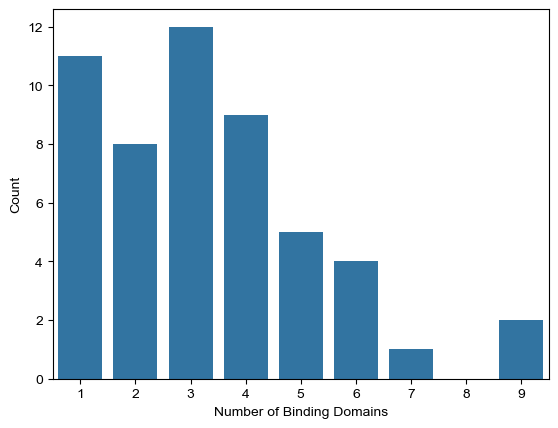

In [38]:
# Load in excel file with information if domains are binding proteins
bddf=pd.read_excel('data/Uniprot_domains_in_PDZ_IDR_Cell_junction_non_transmembrane_proteins.xlsx')

# Extract list of domains that are binding domains
tmpdf=bddf[bddf['Protein Binding']=='O']
bdlist=tmpdf['Domains'].tolist()
print(bdlist)

# For each protein with a PDZ domain (and IDR and in cell junction) count the number of binding domains it includes
numdomainsinPDZ=[]
uniPDZgte3=[]
for i in range(0,len(uniPDZ)):
    tmpdf=cjdomaindf[cjdomaindf['Accession']==uniPDZ[i]]
    tlen=len(tmpdf)
    tmpdf=tmpdf[tmpdf['Domain name no num'].isin(bdlist)]
    numdomainsinPDZ.append(len(tmpdf))
    # Get unique proteins with at least 3 binding domains
    if len(tmpdf)>=3:
        uniPDZgte3.append(uniPDZ[i])
    # Below are a couple checks to test grabbing right domains 
    # if tlen!=len(tmpdf):
    #     print(cjdomaindf[cjdomaindf['Accession']==uniPDZ[i]])
    #     print(tlen)
    #     print(len(tmpdf))
    # if len(tmpdf)==1:
    #     print(cjdomaindf[cjdomaindf['Accession']==uniPDZ[i]])
    
print(' ')
print('Number of proteins with PDZ domains (and IDR and in cell junction): '+str(len(uniPDZ)))
#print(len(numdomainsinPDZ))

# Create dataframe of counts
countnd=[]
nd=[]
for i in range(min(numdomainsinPDZ),max(numdomainsinPDZ)+1):
    nd.append(i)
    countnd.append(numdomainsinPDZ.count(i))
    print(str(i)+': '+str(numdomainsinPDZ.count(i)))
    
bdcountdf=pd.DataFrame()
bdcountdf['Number of Binding Domains']=nd
bdcountdf['Count']=countnd
print(bdcountdf)

sbn.barplot(data=bdcountdf,x='Number of Binding Domains',y='Count')

# Save to excel file
#bdcountdf.to_excel('output/Count_of_binding_domains_in_each_protein_w_PDZ_and_IDR_and_in_cell_junction_without_transmembrane.xlsx')

## 1.10 - Count number of IDRs in proteins with PDZ domains

Number of proteins with PDZ domains (and IDR and in cell junction): 52
52
1: 13
2: 17
3: 9
4: 7
5: 4
6: 0
7: 0
8: 1
9: 0
10: 0
11: 1
    Number of IDRs  Count
0                1     13
1                2     17
2                3      9
3                4      7
4                5      4
5                6      0
6                7      0
7                8      1
8                9      0
9               10      0
10              11      1


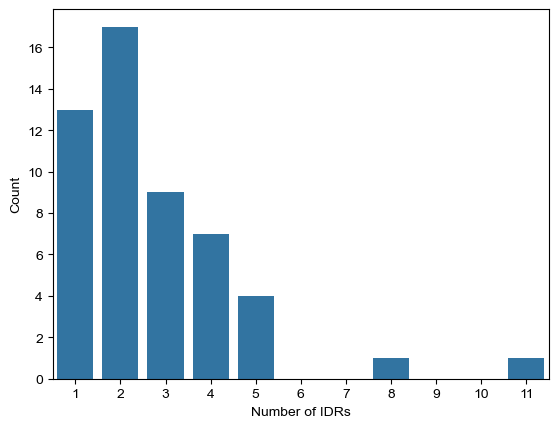

In [42]:
# Count number of IDRs in each PDZ and IDR protein in cell junction and no transmembrane domain
numIDRsinPDZ=[]
uniIDRgte2=[]
for i in range(0,len(uniPDZ)):
    tmpdf=subidrsdfNODIST[subidrsdfNODIST['Uniprot']==uniPDZ[i]]
    numIDRsinPDZ.append(len(tmpdf))
    # Get unique proteins with at least 2 IDRs
    if len(tmpdf)>=2:
        uniIDRgte2.append(uniPDZ[i])
#     if len(tmpdf)==3:
#         print(tmpdf)
    
print('Number of proteins with PDZ domains (and IDR and in cell junction): '+str(len(uniPDZ)))
print(len(numIDRsinPDZ))
 
# Create dataframe of counts
ni=[]
countni=[]
for i in range(min(numIDRsinPDZ),max(numIDRsinPDZ)+1):
    print(str(i)+': '+str(numIDRsinPDZ.count(i)))
    ni.append(i)
    countni.append(numIDRsinPDZ.count(i))
    
idrcountdf=pd.DataFrame()
idrcountdf['Number of IDRs']=ni
idrcountdf['Count']=countni
print(idrcountdf)

sbn.barplot(data=idrcountdf,x='Number of IDRs',y='Count')


#print(len(uniIDRgte2))

# Save to excel file
#idrcountdf.to_excel('output/Count_of_IDRs_in_each_protein_w_PDZ_and_IDR_and_in_cell_junction_without_transmembrane.xlsx')